Cell 1 — Load the QC dataset

In [2]:
!pip -q install scanpy

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from scipy import sparse

BASE_DIR = Path(
    "/content/drive/MyDrive/spatial_transcriptomics"
)

QC_PATH = BASE_DIR / "xenium_breast_cancer_qc.h5ad"
ORIGINAL_PATH = BASE_DIR / "xenium_breast_cancer.h5ad"

DATA_PATH = QC_PATH if QC_PATH.exists() else ORIGINAL_PATH

RESULTS_DIR = BASE_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

adata = sc.read_h5ad(DATA_PATH)

print("Loaded:", DATA_PATH.name)
print("Cells:", adata.n_obs)
print("Genes:", adata.n_vars)
print("Spatial coordinates:", adata.obsm["spatial"].shape)

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Loaded: xenium_breast_cancer_qc.h5ad
Cells: 167780
Genes: 313
Spatial coordinates: (167780, 2)


Cell 2 — Check the spatial coordinates

In [3]:
coords = np.asarray(adata.obsm["spatial"])

assert coords.shape == (adata.n_obs, 2)
assert np.isfinite(coords).all()

x = coords[:, 0]
y = coords[:, 1]

print("X range:", x.min(), "to", x.max())
print("Y range:", y.min(), "to", y.max())
print("Cells with valid coordinates:", len(coords))

X range: 2.1325160980224607 to 7523.086865234375
Y range: 1.3671555936336517 to 5476.26611328125
Cells with valid coordinates: 167780


Cell 3 — Plot all cells

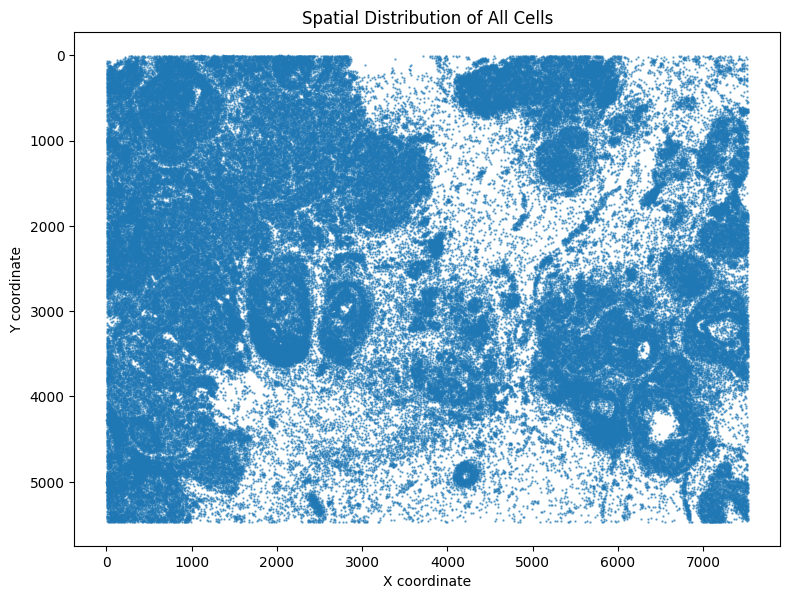

In [4]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    x, y,
    s=0.5,
    alpha=0.6,
    rasterized=True
)

ax.set_title("Spatial Distribution of All Cells")
ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.set_aspect("equal")
ax.invert_yaxis()

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "spatial_all_cells.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Cell 4 — Create a reusable gene-expression plotting function

In [6]:
def get_expression(gene):
    """Return expression values for one gene across all cells."""
    if gene not in adata.var_names:
        raise ValueError(
            f"{gene} is not in the gene panel. "
            "Check adata.var_names."
        )

    values = adata[:, gene].X

    if sparse.issparse(values):
        values = values.toarray()

    return np.asarray(values).ravel()


def plot_spatial_gene(gene, save=True):
    """Plot a gene's expression at each cell's spatial position."""
    values = get_expression(gene)
    detected = values > 0

    fig, ax = plt.subplots(figsize=(8, 8))

    # Background: cells with no detected expression
    ax.scatter(
        x[~detected], y[~detected],
        s=0.5, c="lightgray", alpha=0.35,
        rasterized=True, label="Not detected"
    )

    # Foreground: cells with detected expression
    if detected.any():
        points = ax.scatter(
            x[detected], y[detected],
            c=values[detected],
            s=1.2,
            cmap="Reds",
            alpha=0.9,
            rasterized=True
        )
        fig.colorbar(points, ax=ax, label="Expression value")

    ax.set_title(f"Spatial Expression: {gene}")
    ax.set_xlabel("X coordinate")
    ax.set_ylabel("Y coordinate")
    ax.set_aspect("equal")
    ax.invert_yaxis()

    percent = detected.mean() * 100
    ax.text(
        0.02, 0.02,
        f"Detected in {percent:.1f}% of cells",
        transform=ax.transAxes,
        fontsize=10,
        bbox={"facecolor": "white", "alpha": 0.8}
    )

    plt.tight_layout()

    if save:
        filename = FIGURES_DIR / f"spatial_{gene}.png"
        plt.savefig(filename, dpi=300, bbox_inches="tight")
        print("Saved:", filename.name)

    plt.show()

Cell 5 — Visualize epithelial-associated markers

Saved: spatial_EPCAM.png


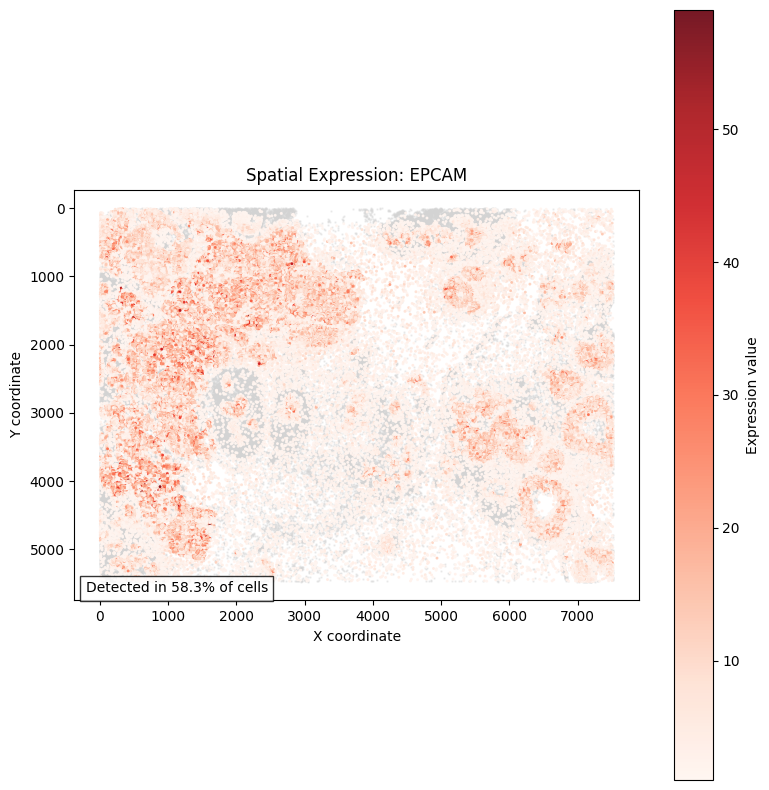

Saved: spatial_KRT8.png


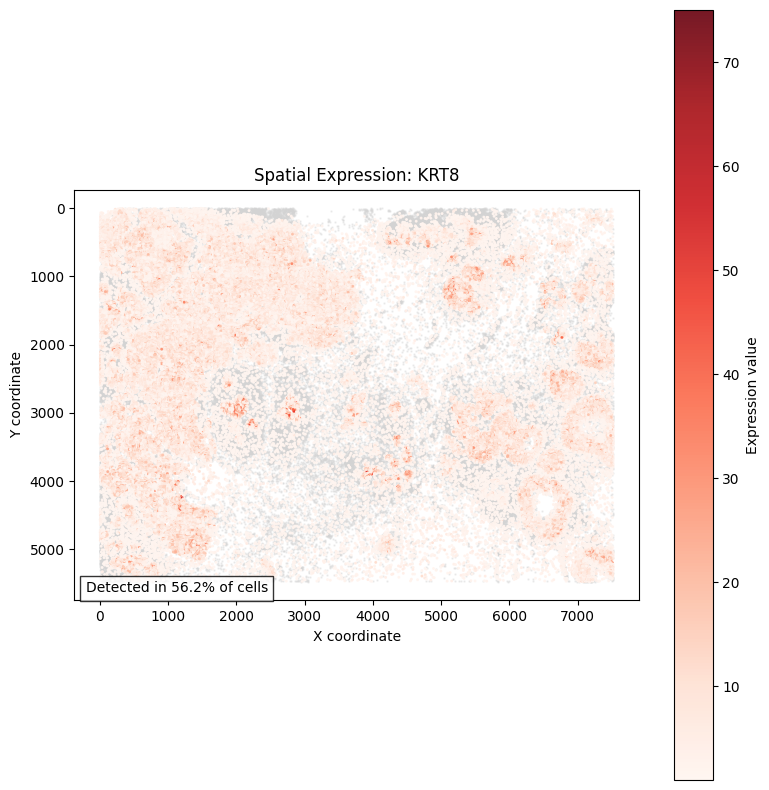

In [7]:
for gene in ["EPCAM", "KRT8"]:
    if gene in adata.var_names:
        plot_spatial_gene(gene)
    else:
        print(f"Skipping {gene}: not available")

Cell 6 — Visualize immune-associated markers

Saved: spatial_PTPRC.png


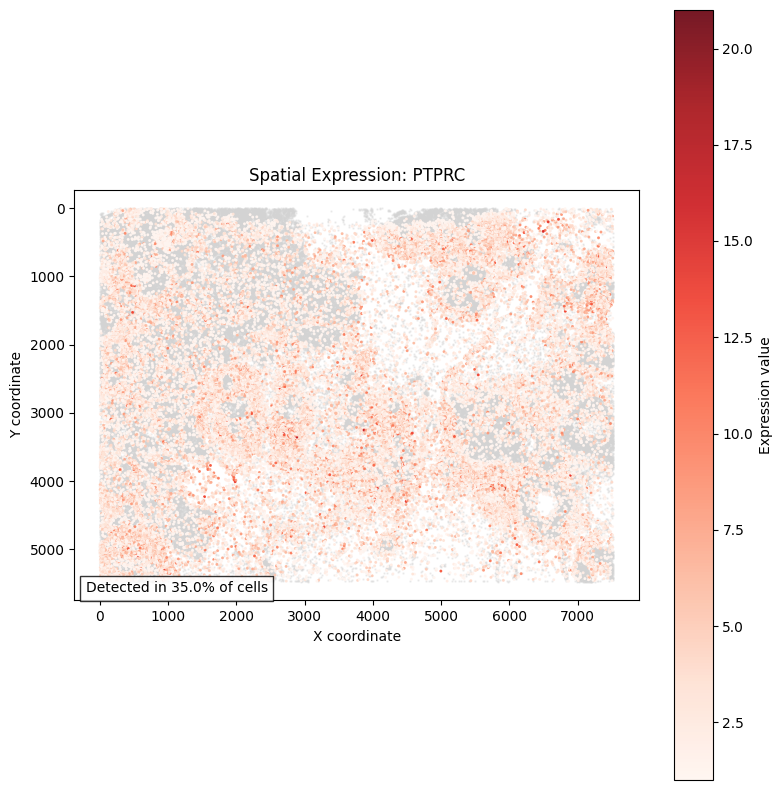

Saved: spatial_CD68.png


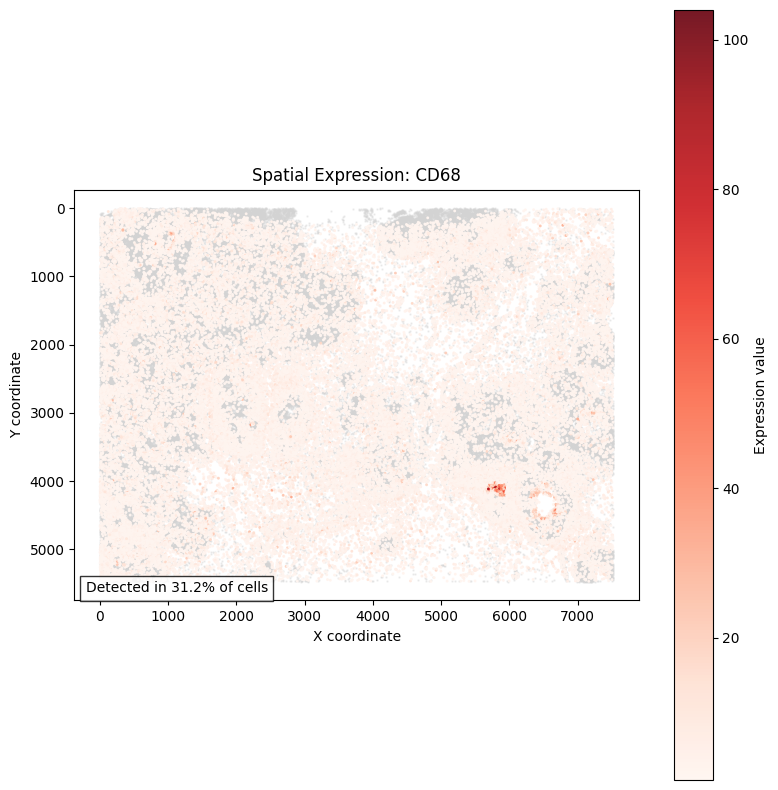

Saved: spatial_CD3E.png


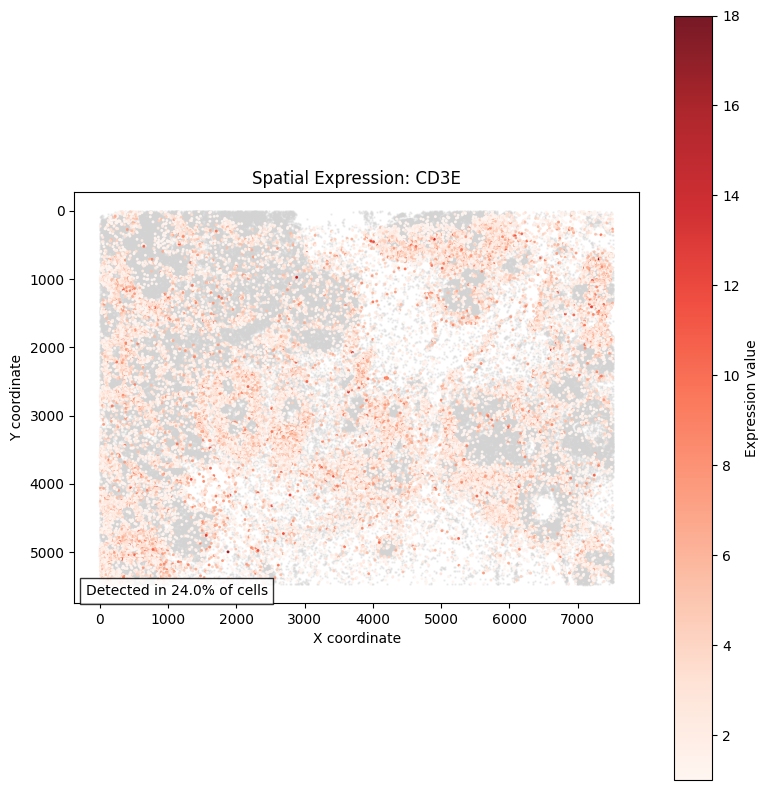

Saved: spatial_MS4A1.png


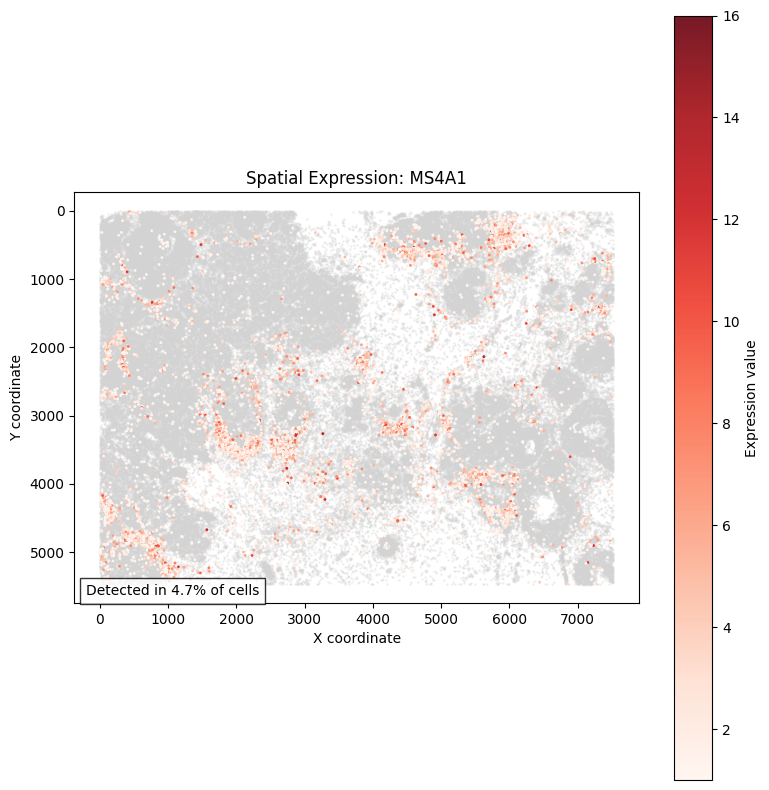

In [8]:
for gene in ["PTPRC", "CD68", "CD3E", "MS4A1"]:
    if gene in adata.var_names:
        plot_spatial_gene(gene)
    else:
        print(f"Skipping {gene}: not available")

Cell 7 — Compare marker detection across the tissue

In [9]:
genes_to_plot = [
    gene for gene in [
        "EPCAM", "KRT8", "PTPRC",
        "CD68", "CD3D", "CD3E",
        "MS4A1", "ACTA2", "PECAM1"
    ]
    if gene in adata.var_names
]

detection_rows = []

for gene in genes_to_plot:
    values = get_expression(gene)
    detected = values > 0

    detection_rows.append({
        "gene": gene,
        "cells_detected": int(detected.sum()),
        "percent_cells_detected": float(detected.mean() * 100),
        "mean_expression": float(values.mean()),
    })

detection_summary = pd.DataFrame(detection_rows)

print(detection_summary.round(3).to_string(index=False))

detection_summary.to_csv(
    RESULTS_DIR / "spatial_visualization_detection_summary.csv",
    index=False
)

  gene  cells_detected  percent_cells_detected  mean_expression
 EPCAM           97872                  58.334            4.245
  KRT8           94250                  56.175            3.094
 PTPRC           58747                  35.014            0.975
  CD68           52419                  31.243            0.815
  CD3D           19390                  11.557            0.166
  CD3E           40249                  23.989            0.601
 MS4A1            7928                   4.725            0.117
 ACTA2           94179                  56.132            1.894
PECAM1           42764                  25.488            0.713


Cell 8 — Save a multi-panel marker overview

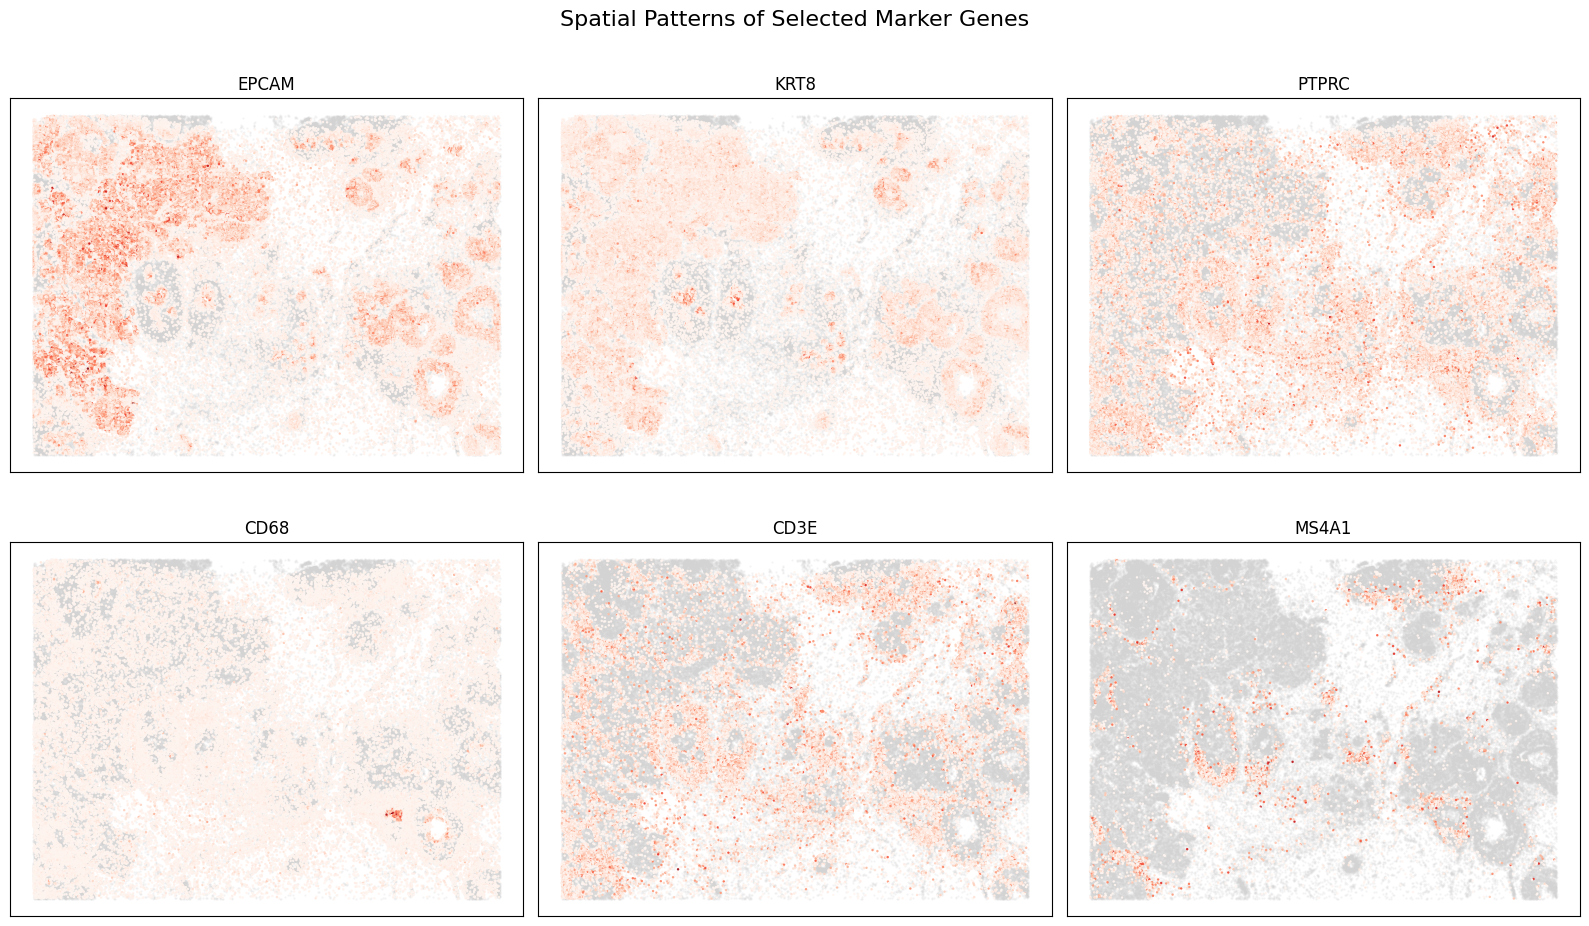

Saved: /content/drive/MyDrive/spatial_transcriptomics/results/figures/spatial_marker_panel.png


In [10]:
genes_for_panel = [
    gene for gene in [
        "EPCAM", "KRT8", "PTPRC",
        "CD68", "CD3E", "MS4A1"
    ]
    if gene in adata.var_names
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10)
)
axes = axes.ravel()

for ax, gene in zip(axes, genes_for_panel):
    values = get_expression(gene)
    detected = values > 0

    ax.scatter(
        x[~detected], y[~detected],
        s=0.25, c="lightgray", alpha=0.25,
        rasterized=True
    )

    if detected.any():
        ax.scatter(
            x[detected], y[detected],
            s=0.6, c=values[detected],
            cmap="Reds", alpha=0.85,
            rasterized=True
        )

    ax.set_title(gene)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_xticks([])
    ax.set_yticks([])

for ax in axes[len(genes_for_panel):]:
    ax.axis("off")

fig.suptitle(
    "Spatial Patterns of Selected Marker Genes",
    fontsize=16
)
plt.tight_layout()

panel_path = FIGURES_DIR / "spatial_marker_panel.png"
plt.savefig(panel_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", panel_path)

Cell 9 — Save a reproducibility summary

In [11]:
from datetime import datetime, timezone
import json

visualization_manifest = {
    "notebook": "03_spatial_visualization.ipynb",
    "input_file": DATA_PATH.name,
    "n_cells": int(adata.n_obs),
    "n_genes": int(adata.n_vars),
    "coordinate_key": "spatial",
    "genes_visualized": genes_to_plot,
    "figures_directory": str(FIGURES_DIR),
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "interpretation_note": (
        "Marker expression maps show spatial detection patterns. "
        "They do not independently establish cell identity, "
        "malignancy, or tumor boundaries."
    ),
}

manifest_path = RESULTS_DIR / "spatial_visualization_manifest.json"

with open(manifest_path, "w") as f:
    json.dump(visualization_manifest, f, indent=2)

print("Visualization outputs saved.")
print("Figures folder:", FIGURES_DIR)
print("Manifest:", manifest_path)

Visualization outputs saved.
Figures folder: /content/drive/MyDrive/spatial_transcriptomics/results/figures
Manifest: /content/drive/MyDrive/spatial_transcriptomics/results/spatial_visualization_manifest.json
